In [ ]:

from roboflow import Roboflow

rf = Roboflow(api_key="P5piyUkvrMQTzTSOMWvZ")

project = rf.workspace("hemanth-g").project(
    "helmet-number-plate-detec/tion-2-dhicg"
)
dataset = project.version(1).download("yolov8")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...


RuntimeError: The helmet-number-plate-detec/tion-2-dhicg project is not available in this (hemanth-g) workspace

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="P5piyUkvrMQTzTSOMWvZ")

project = rf.workspace("hemanth-g").project(
    "helmet-number-plate-detection-2-dhicg"
)

dataset = project.version(1).download("yolov8")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to Helmet-&-Number-Plate-Detection-2-1 in yolov8:: 100%|█| 10752/10752 [00:17<00:00, 604


Dataset location: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1


In [ ]:
import os

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

print(os.listdir(dataset_path))

['data.yaml', 'README.roboflow.txt', 'test', 'train', 'valid']


In [ ]:
for split in ["train", "valid", "test"]:
    image_path = os.path.join(dataset_path, split, "images")

    if os.path.exists(image_path):
        print(f"{split}: {len(os.listdir(image_path))} images")
    else:
        print(f"{split}: images folder not found")

train: 4382 images
valid: 616 images
test: 376 images


In [ ]:
for split in ["train", "valid", "test"]:
    label_path = os.path.join(dataset_path, split, "labels")

    if os.path.exists(label_path):
        print(f"{split}: {len(os.listdir(label_path))} labels")
    else:
        print(f"{split}: labels folder not found")

train: 4382 labels
valid: 616 labels
test: 376 labels


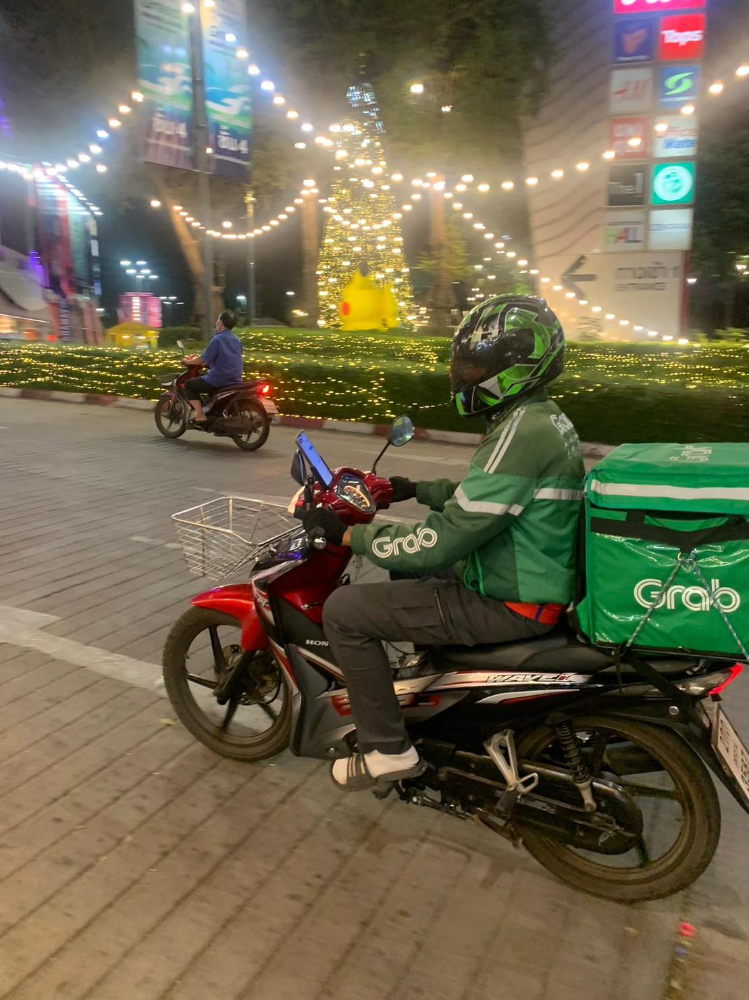

In [ ]:
from PIL import Image

image_path = os.path.join(
    dataset_path,
    "train",
    "images",
    os.listdir(os.path.join(dataset_path, "train", "images"))[0]
)

display(Image.open(image_path))

In [ ]:
dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

In [ ]:
import os
from collections import Counter

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

# Read class names from data.yaml
import yaml

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

names = data["names"]

print("Classes:")
for class_id, class_name in enumerate(names):
    print(f"  {class_id}: {class_name}")

print("\nDataset:")
print("Location:", dataset_path)

# Count images and labels
for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    ]

    print(f"\n{split.upper()}")
    print("  Images :", len(images))
    print("  Labels :", len(labels))

    # Count annotations by class
    class_counts = Counter()

    for label_file in labels:
        label_path = os.path.join(label_dir, label_file)

        with open(label_path, "r") as f:
            for line in f:
                line = line.strip()

                if not line:
                    continue

                parts = line.split()

                if len(parts) >= 5:
                    class_id = int(parts[0])
                    class_counts[class_id] += 1

    print("  Annotations:")
    for class_id, count in sorted(class_counts.items()):
        print(f"    {class_id} ({names[class_id]}): {count}")

Classes:
  0: helmet
  1: no_helmet
  2: number_plate
  3: pillion
  4: rider

Dataset:
Location: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1

TRAIN
  Images : 4382
  Labels : 4382
  Annotations:
    0 (helmet): 3266
    1 (no_helmet): 3043
    2 (number_plate): 503
    3 (pillion): 425
    4 (rider): 1678

VALID
  Images : 616
  Labels : 616
  Annotations:
    0 (helmet): 452
    1 (no_helmet): 596
    2 (number_plate): 83
    3 (pillion): 56
    4 (rider): 165

TEST
  Images : 376
  Labels : 376
  Annotations:
    0 (helmet): 257
    1 (no_helmet): 171
    2 (number_plate): 68
    3 (pillion): 55
    4 (rider): 210


In [ ]:
import os

valid_classes = {0, 1, 2, 3, 4}

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    image_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    }

    label_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    }

    empty_labels = []
    malformed_labels = []
    invalid_class = []
    invalid_coordinates = []

    # Check every label
    for label_file in label_files:
        label_path = os.path.join(label_dir, label_file + ".txt")

        with open(label_path, "r") as f:
            lines = f.readlines()

        # Empty file
        if len(lines) == 0 or all(not line.strip() for line in lines):
            empty_labels.append(label_file)
            continue

        for line_number, line in enumerate(lines, start=1):
            line = line.strip()

            if not line:
                continue

            parts = line.split()

            # YOLO format should have:
            # class_id x_center y_center width height
            if len(parts) != 5:
                malformed_labels.append(
                    (label_file, line_number, line)
                )
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                malformed_labels.append(
                    (label_file, line_number, line)
                )
                continue

            # Invalid class
            if class_id not in valid_classes:
                invalid_class.append(
                    (label_file, line_number, class_id)
                )

            # YOLO coordinates should be between 0 and 1
            if not all(0 <= value <= 1 for value in [x, y, w, h]):
                invalid_coordinates.append(
                    (label_file, line_number, [x, y, w, h])
                )

    images_without_labels = image_files - label_files
    labels_without_images = label_files - image_files

    print("=" * 60)
    print(split.upper())

    print("Images without labels :", len(images_without_labels))
    print("Labels without images :", len(labels_without_images))
    print("Empty label files    :", len(empty_labels))
    print("Malformed annotations:", len(malformed_labels))
    print("Invalid class IDs    :", len(invalid_class))
    print("Invalid coordinates  :", len(invalid_coordinates))

TRAIN
Images without labels : 0
Labels without images : 0
Empty label files    : 12
Malformed annotations: 0
Invalid class IDs    : 0
Invalid coordinates  : 0
VALID
Images without labels : 0
Labels without images : 0
Empty label files    : 2
Malformed annotations: 0
Invalid class IDs    : 0
Invalid coordinates  : 0
TEST
Images without labels : 0
Labels without images : 0
Empty label files    : 0
Malformed annotations: 0
Invalid class IDs    : 0
Invalid coordinates  : 0


In [ ]:
import os
for split in ["train", "valid", "test"]:
    label_dir = os.path.join(dataset_path, split, "labels")
    image_dir = os.path.join(dataset_path, split, "images")

    for label_file in os.listdir(label_dir):

        if not label_file.endswith(".txt"):
            continue

        label_path = os.path.join(label_dir, label_file)

        if os.path.getsize(label_path) == 0:

            base_name = os.path.splitext(label_file)[0]

            possible_images = [
                f"{base_name}.jpg",
                f"{base_name}.jpeg",
                f"{base_name}.png",
                f"{base_name}.webp",
            ]

            image_path = None

            for image_name in possible_images:
                candidate = os.path.join(image_dir, image_name)

                if os.path.exists(candidate):
                    image_path = candidate
                    break

            print(f"{split}:")
            print("  Image:", image_path)
            print("  Label:", label_path)

train:
  Image: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\images\BikesHelmets116_png.rf.368f323f9bf2e408a1f0a58850f131c7.jpg
  Label: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\labels\BikesHelmets116_png.rf.368f323f9bf2e408a1f0a58850f131c7.txt
train:
  Image: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\images\IMG_0447_MOV-5_jpg.rf.6338c5857c90926867ead7e8bc022af3.jpg
  Label: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\labels\IMG_0447_MOV-5_jpg.rf.6338c5857c90926867ead7e8bc022af3.txt
train:
  Image: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\images\LINE_ALBUM_13102566-BE_231013_75_jpg.rf.8d1471492cef798a9da3769310733c9e.jpg
  Label: C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1\train\labels\LINE_ALBUM_13102566-BE_231013_75_jpg.rf.8d1471492cef798a9da3769310733c9e.txt
train:
  Image: C:\Users\heman\computervision\Helmet-&-Numb

Total empty-label images: 14


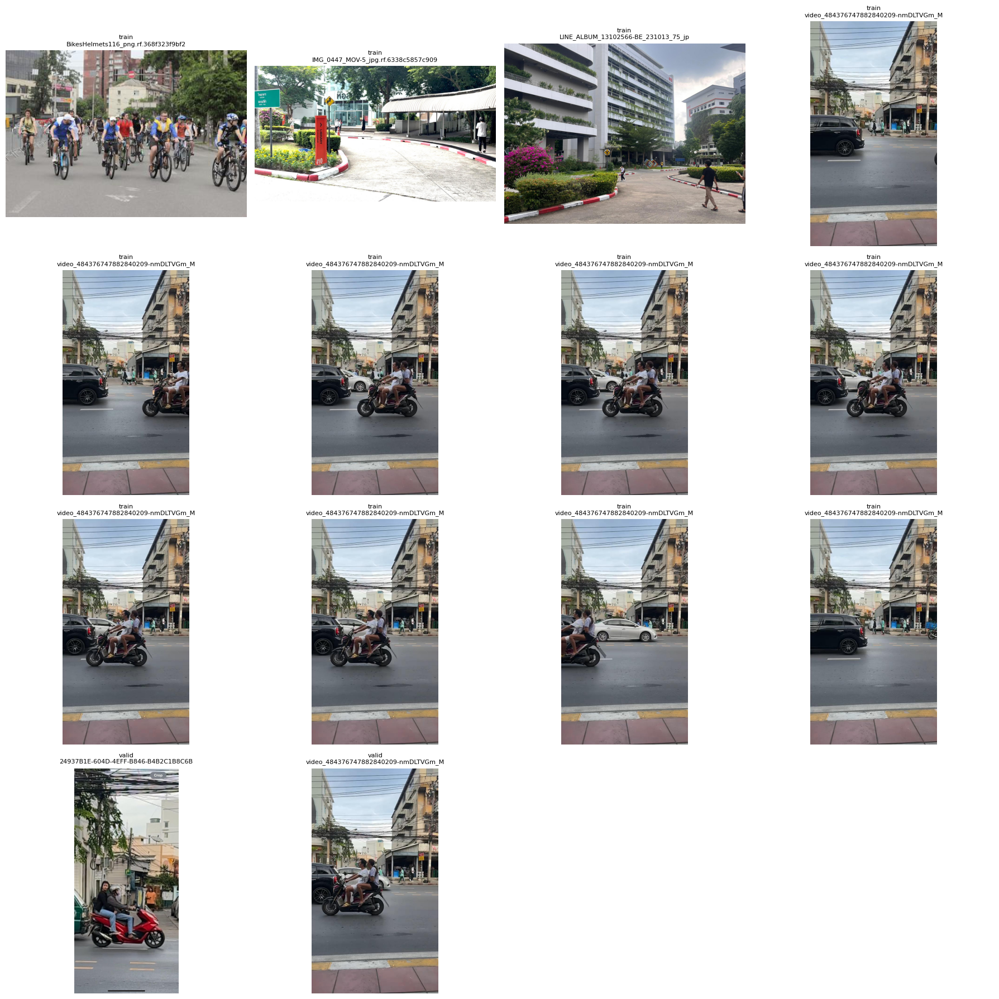

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

empty_images = []

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    for label_file in os.listdir(label_dir):
        if not label_file.endswith(".txt"):
            continue

        label_path = os.path.join(label_dir, label_file)

        if os.path.getsize(label_path) == 0:
            base_name = os.path.splitext(label_file)[0]

            for ext in [".jpg", ".jpeg", ".png", ".webp"]:
                image_path = os.path.join(image_dir, base_name + ext)

                if os.path.exists(image_path):
                    empty_images.append((split, image_path))
                    break

print("Total empty-label images:", len(empty_images))

# Display
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for i, (split, image_path) in enumerate(empty_images):
    img = Image.open(image_path)

    axes[i].imshow(img)
    axes[i].set_title(
        f"{split}\n{os.path.basename(image_path)[:35]}",
        fontsize=8
    )
    axes[i].axis("off")

# Hide unused plots
for i in range(len(empty_images), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

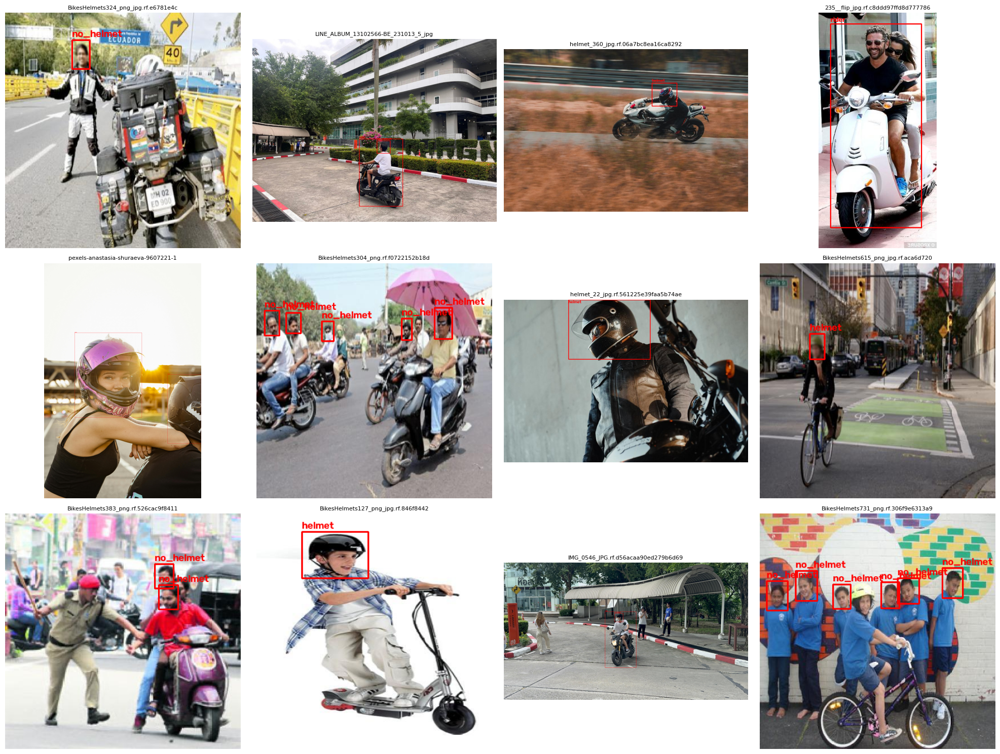

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

class_names = {
    0: "helmet",
    1: "no_helmet",
    2: "number_plate",
    3: "pillion",
    4: "rider"
}

# Select images from training set
image_dir = os.path.join(dataset_path, "train", "images")
label_dir = os.path.join(dataset_path, "train", "labels")

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

# Randomly select 12 images that have non-empty labels
selected = []

while len(selected) < 12:
    image_name = random.choice(images)
    label_name = os.path.splitext(image_name)[0] + ".txt"
    label_path = os.path.join(label_dir, label_name)

    if os.path.exists(label_path) and os.path.getsize(label_path) > 0:
        if image_name not in selected:
            selected.append(image_name)

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for idx, image_name in enumerate(selected):

    image_path = os.path.join(image_dir, image_name)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(image_name)[0] + ".txt"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()

        if len(parts) != 5:
            continue

        class_id = int(parts[0])
        x_center, y_center, box_w, box_h = map(float, parts[1:])

        # Convert YOLO coordinates to pixel coordinates
        x1 = int((x_center - box_w / 2) * w)
        y1 = int((y_center - box_h / 2) * h)
        x2 = int((x_center + box_w / 2) * w)
        y2 = int((y_center + box_h / 2) * h)

        # Draw bounding box
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        # Draw class name
        label = class_names.get(class_id, f"class_{class_id}")

        cv2.putText(
            image,
            label,
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    axes[idx].imshow(image)
    axes[idx].set_title(image_name[:35], fontsize=8)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import os
from collections import Counter

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")

    sizes = []

    for file in os.listdir(image_dir):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            path = os.path.join(image_dir, file)

            try:
                with Image.open(path) as img:
                    sizes.append(img.size)
            except Exception as e:
                print("Could not read:", file, e)

    counter = Counter(sizes)

    print("\n" + "=" * 50)
    print(split.upper())
    print("Images:", len(sizes))
    print("Unique resolutions:", len(counter))

    print("\nMost common resolutions:")
    for size, count in counter.most_common(10):
        print(f"  {size[0]} x {size[1]} : {count}")


TRAIN
Images: 4382
Unique resolutions: 698

Most common resolutions:
  416 x 416 : 1702
  640 x 640 : 522
  1920 x 1080 : 164
  1080 x 1920 : 88
  1080 x 1620 : 70
  1080 x 720 : 69
  3520 x 1980 : 64
  1479 x 1109 : 57
  400 x 267 : 53
  4032 x 3024 : 42

VALID
Images: 616
Unique resolutions: 246

Most common resolutions:
  416 x 416 : 119
  640 x 640 : 80
  400 x 267 : 21
  1080 x 720 : 21
  1920 x 1080 : 16
  400 x 225 : 14
  3520 x 1980 : 13
  400 x 300 : 12
  1080 x 1620 : 10
  1536 x 2728 : 9

TEST
Images: 376
Unique resolutions: 138

Most common resolutions:
  640 x 640 : 67
  416 x 416 : 56
  3520 x 1980 : 25
  1920 x 1080 : 17
  1479 x 1109 : 13
  1080 x 1620 : 11
  1080 x 720 : 8
  1080 x 1350 : 6
  4032 x 3024 : 5
  400 x 300 : 4


In [ ]:
import os
from collections import defaultdict

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

class_names = {
    0: "helmet",
    1: "no_helmet",
    2: "number_plate",
    3: "pillion",
    4: "rider"
}

box_stats = defaultdict(list)

for split in ["train", "valid", "test"]:
    label_dir = os.path.join(dataset_path, split, "labels")

    for file in os.listdir(label_dir):
        if not file.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, file), "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                # normalized bounding-box area
                area = w * h

                box_stats[class_id].append({
                    "split": split,
                    "width": w,
                    "height": h,
                    "area": area
                })

print("=" * 60)
print("BOUNDING BOX SIZE ANALYSIS")
print("=" * 60)

for class_id in range(5):

    boxes = box_stats[class_id]

    areas = [b["area"] for b in boxes]

    if not areas:
        continue

    areas_sorted = sorted(areas)

    n = len(areas_sorted)

    print(f"\n{class_id} - {class_names[class_id]}")
    print("Boxes:", n)

    print(f"Minimum area : {areas_sorted[0]:.6f}")
    print(f"25% area     : {areas_sorted[int(n * 0.25)]:.6f}")
    print(f"Median area  : {areas_sorted[int(n * 0.50)]:.6f}")
    print(f"75% area     : {areas_sorted[int(n * 0.75)]:.6f}")
    print(f"Maximum area : {areas_sorted[-1]:.6f}")

BOUNDING BOX SIZE ANALYSIS

0 - helmet
Boxes: 3975
Minimum area : 0.000374
25% area     : 0.005748
Median area  : 0.013957
75% area     : 0.027043
Maximum area : 0.791134

1 - no_helmet
Boxes: 3810
Minimum area : 0.000231
25% area     : 0.004245
Median area  : 0.009162
75% area     : 0.017272
Maximum area : 0.337185

2 - number_plate
Boxes: 654
Minimum area : 0.001318
25% area     : 0.013589
Median area  : 0.020403
75% area     : 0.050725
Maximum area : 0.896416

3 - pillion
Boxes: 536
Minimum area : 0.001700
25% area     : 0.008940
Median area  : 0.031060
75% area     : 0.077607
Maximum area : 0.280294

4 - rider
Boxes: 2053
Minimum area : 0.002980
25% area     : 0.070075
Median area  : 0.203700
75% area     : 0.408108
Maximum area : 1.000000


In [ ]:
areas = [b["area"] for b in box_stats[2]]

thresholds = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]

print("=" * 60)
print("NUMBER PLATE SMALL-BOX ANALYSIS")
print("=" * 60)

total = len(areas)

for threshold in thresholds:
    count = sum(a < threshold for a in areas)
    percentage = (count / total) * 100

    print(
        f"Area < {threshold:<6} : "
        f"{count:4d} / {total} "
        f"({percentage:.2f}%)"
    )

NUMBER PLATE SMALL-BOX ANALYSIS
Area < 0.001  :    0 / 654 (0.00%)
Area < 0.0025 :    7 / 654 (1.07%)
Area < 0.005  :   30 / 654 (4.59%)
Area < 0.01   :   99 / 654 (15.14%)
Area < 0.02   :  318 / 654 (48.62%)
Area < 0.05   :  486 / 654 (74.31%)


In [ ]:
import os
from collections import Counter

dataset_path = r"C:\Users\heman\computervision\Helmet-&-Number-Plate-Detection-2-1"

class_names = {
    0: "helmet",
    1: "no_helmet",
    2: "number_plate",
    3: "pillion",
    4: "rider"
}

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset_path, split, "labels")

    image_count = 0
    images_with_class = Counter()
    boxes_per_image = []

    for file in os.listdir(label_dir):

        if not file.endswith(".txt"):
            continue

        image_count += 1

        classes_in_image = set()
        box_count = 0

        with open(os.path.join(label_dir, file), "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])

                classes_in_image.add(class_id)
                box_count += 1

        for class_id in classes_in_image:
            images_with_class[class_id] += 1

        boxes_per_image.append(box_count)

    print("\n" + "=" * 60)
    print(split.upper())
    print("=" * 60)

    print(f"Images: {image_count}")

    for class_id in range(5):
        count = images_with_class[class_id]
        percentage = (count / image_count) * 100

        print(
            f"{class_names[class_id]:<15}: "
            f"{count:4d} images "
            f"({percentage:6.2f}%)"
        )

    print(f"\nAverage boxes/image: {sum(boxes_per_image)/len(boxes_per_image):.2f}")
    print(f"Maximum boxes/image: {max(boxes_per_image)}")


TRAIN
Images: 4382
helmet         : 1833 images ( 41.83%)
no_helmet      : 1674 images ( 38.20%)
number_plate   :  486 images ( 11.09%)
pillion        :  363 images (  8.28%)
rider          : 1465 images ( 33.43%)

Average boxes/image: 2.03
Maximum boxes/image: 27

VALID
Images: 616
helmet         :  285 images ( 46.27%)
no_helmet      :  329 images ( 53.41%)
number_plate   :   69 images ( 11.20%)
pillion        :   50 images (  8.12%)
rider          :  139 images ( 22.56%)

Average boxes/image: 2.19
Maximum boxes/image: 11

TEST
Images: 376
helmet         :  161 images ( 42.82%)
no_helmet      :  104 images ( 27.66%)
number_plate   :   65 images ( 17.29%)
pillion        :   47 images ( 12.50%)
rider          :  182 images ( 48.40%)

Average boxes/image: 2.02
Maximum boxes/image: 10


In [ ]:
!pip install ultralytics
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------------- ---------- 1.0/1.4 MB 9.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 8.3 MB/s  0:00:00
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.6/44.0 MB 14.9 MB/s eta 0:00:03
   ---- ----------------------------------- 4.7/44.0 MB 11.0 MB/s eta 0:00:04
   -------- ------------------------------- 9.4/44.0 MB 15.0 MB/s eta 0:00:03
   ------------- -------------------------- 14.4/44.0 MB 17.3 MB/s eta 0:00:02
   ---------------- ----------------------- 18.6/44.0 MB 17.8 MB/s eta 0:00:02
   ---------------------- ----------------- 24.4/44.0 MB 19.2 MB/s eta 0:00:02
   ------------------------- -------------- 28.3/44.0 MB 19.1 MB/s eta 0:00:01
   ------------------------------ --------- 34.1/44.0 MB 20.1 MB/s eta 0:00:01
   ----------------------------------- ---- 39.6/44.0 MB 20.7 MB/s eta 0:00:01
   -

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/computervision"

for item in os.listdir(project_path):
    print(item)

trafficproject.ipynb
.ipynb_checkpoints
Helmet-&-Number-Plate-Detection-2-1
runs
error_analysis


In [ ]:
dataset_path = os.path.join(
    project_path,
    "Helmet-&-Number-Plate-Detection-2-1"
)

print("Dataset path:", dataset_path)
print("Exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("\nDataset contents:")
    print(os.listdir(dataset_path))

Dataset path: /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1
Exists: True

Dataset contents:
['README.roboflow.txt', 'data.yaml', 'train', 'valid', 'test']


In [ ]:
from pathlib import Path

yaml_path = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

print(Path(yaml_path).read_text())

names:
- helmet
- no_helmet
- number_plate
- pillion
- rider
nc: 5
roboflow:
  license: MIT
  project: helmet-number-plate-detection-2-dhicg
  url: https://app.roboflow.com/hemanth-g/helmet-number-plate-detection-2-dhicg/1
  version: 1
  workspace: hemanth-g
test: ../test/images
train: ../train/images
val: ../valid/images



In [ ]:
!pip install ultralytics
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 8.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.166
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -U ultralytics

In [ ]:
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Ultralytics: 8.4.166
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO

dataset_yaml = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

model = YOLO("yolo11n.pt")

print("Model loaded successfully.")
print("Dataset YAML:", dataset_yaml)

Model loaded successfully.
Dataset YAML: /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml


In [ ]:
results = model.val(
    data=dataset_yaml,
    imgsz=640,
    batch=16,
    device=0,
    split="val"
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.0±0.5 ms, read: 0.6±1.0 MB/s, size: 394.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/valid/labels... 616 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 616/616 1.6it/s 6:34
val: New cache created: /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 2.4it/s 16.4s
                   all        616       1352     0.0116      0.129    0.00175   0.000819
                person        285        452     0.0044       0.31    0.00164   0.0

In [ ]:
import yaml

dataset_yaml = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

with open(dataset_yaml, "r") as f:
    data = yaml.safe_load(f)

print(data)
print("\nNames:", data["names"])
print("Number of classes:", data["nc"])

{'names': ['helmet', 'no_helmet', 'number_plate', 'pillion', 'rider'], 'nc': 5, 'roboflow': {'license': 'MIT', 'project': 'helmet-number-plate-detection-2-dhicg', 'url': 'https://app.roboflow.com/hemanth-g/helmet-number-plate-detection-2-dhicg/1', 'version': 1, 'workspace': 'hemanth-g'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}

Names: ['helmet', 'no_helmet', 'number_plate', 'pillion', 'rider']
Number of classes: 5


In [ ]:
print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [ ]:
import os
import shutil

drive_dataset = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1"
local_dataset = "/content/Helmet-&-Number-Plate-Detection-2-1"

if not os.path.exists(local_dataset):
    print("Copying dataset to Colab local storage...")
    shutil.copytree(drive_dataset, local_dataset)
    print("Dataset copied successfully.")
else:
    print("Dataset already exists locally.")

print("\nLocal dataset:")
print(os.listdir(local_dataset))

Copying dataset to Colab local storage...
Dataset copied successfully.

Local dataset:
['README.roboflow.txt', 'test', 'valid', 'train', 'data.yaml']


In [ ]:
from ultralytics import YOLO
import os

# Local dataset
dataset_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

# Load pretrained YOLO11n
model = YOLO("yolo11n.pt")

# Google Drive location for persistent results
project_dir = "/content/drive/MyDrive/computervision/runs"

# Train
results = model.train(
    data=dataset_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,

    # Save training results to Google Drive
    project=project_dir,
    name="yolo11n_helmet_plate_baseline",

    # Save checkpoints
    save=True,
    save_period=10,

    # Training settings
    patience=15,
    workers=2
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_helmet_plate_baseline, nbs

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt"
)

test_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

test_results = model.val(
    data=test_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1276.5±1127.1 MB/s, size: 167.8 KB)
val: Scanning /content/Helmet-&-Number-Plate-Detection-2-1/test/labels... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376 529.2it/s 0.7s
val: New cache created: /content/Helmet-&-Number-Plate-Detection-2-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 2.0it/s 12.2s
                   all        376        761      0.862      0.884      0.916      0.565
                helmet        161        257      0.803      0.807       0.85      0.452
             no_helmet        104        171      0.801      0.799      0.856      0.504
          number_plate         65         68      0.908      0.956      0.947      0.629
               pillion 

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt"
)

model.val(
    data="/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1392.6±704.2 MB/s, size: 320.2 KB)
val: Scanning /content/Helmet-&-Number-Plate-Detection-2-1/test/labels.cache... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376 75.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.9it/s 12.5s
                   all        376        761      0.862      0.884      0.916      0.565
                helmet        161        257      0.803      0.807       0.85      0.452
             no_helmet        104        171      0.801      0.799      0.856      0.504
          number_plate         65         68      0.908      0.956      0.947      0.629
               pillion         47         55      0.908      0.909      0.947      0.508
                

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fa3d8ed3c40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [ ]:
import os

results_dir = "/content/runs/detect/val-3"

print(os.listdir(results_dir))

['BoxR_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix_normalized.png', 'val_batch1_pred.jpg', 'val_batch1_labels.jpg', 'BoxPR_curve.png', 'BoxP_curve.png', 'val_batch2_labels.jpg', 'confusion_matrix.png', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'BoxF1_curve.png']


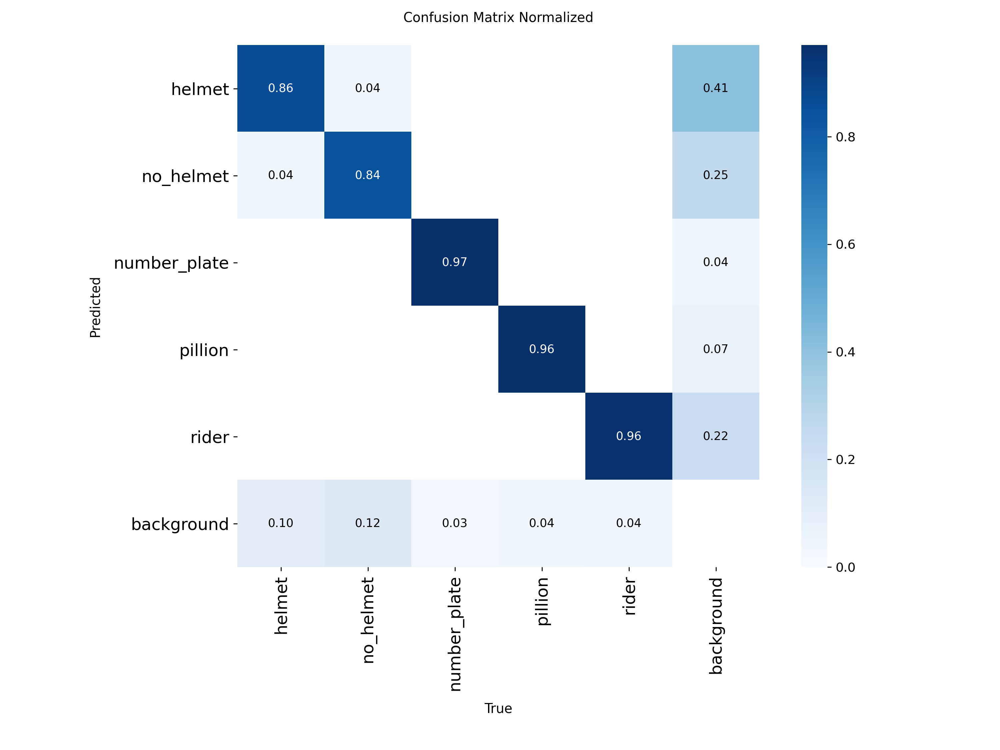

In [ ]:
from IPython.display import Image, display

display(Image(
    filename="/content/runs/detect/val-3/confusion_matrix_normalized.png"
))

In [ ]:
from ultralytics import YOLO
import os
import random
from IPython.display import display, Image

# Load our trained model
model = YOLO(
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

# Validation images
val_dir = "/content/Helmet-&-Number-Plate-Detection-2-1/valid/images"

# Get validation images
images = [
    os.path.join(val_dir, f)
    for f in os.listdir(val_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Validation images:", len(images))

# Random sample
random.seed(42)
sample = random.sample(images, min(20, len(images)))

print("Running predictions on", len(sample), "validation images...")

results = model.predict(
    source=sample,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    save_conf=True,
    project="/content/drive/MyDrive/computervision/error_analysis",
    name="val_sample",
    exist_ok=True
)

print("\nSaved predictions to:")
print("/content/drive/MyDrive/computervision/error_analysis/val_sample")

Validation images: 616
Running predictions on 20 validation images...

0: 640x640 2 helmets, 4.5ms
1: 640x640 2 number_plates, 4.5ms
2: 640x640 1 rider, 4.5ms
3: 640x640 1 helmet, 4.5ms
4: 640x640 1 helmet, 1 rider, 4.5ms
5: 640x640 1 helmet, 2 no_helmets, 2 pillions, 1 rider, 4.5ms
6: 640x640 2 helmets, 2 no_helmets, 5 riders, 4.5ms
7: 640x640 4 number_plates, 4.5ms
8: 640x640 1 number_plate, 4.5ms
9: 640x640 7 no_helmets, 6 pillions, 4.5ms
10: 640x640 3 helmets, 4.5ms
11: 640x640 1 rider, 4.5ms
12: 640x640 1 helmet, 4.5ms
13: 640x640 2 no_helmets, 4.5ms
14: 640x640 2 helmets, 1 no_helmet, 1 pillion, 2 riders, 4.5ms
15: 640x640 1 helmet, 4.5ms
16: 640x640 1 helmet, 1 rider, 4.5ms
17: 640x640 1 no_helmet, 1 rider, 4.5ms
18: 640x640 1 rider, 4.5ms
19: 640x640 2 helmets, 4.5ms
Speed: 1.8ms preprocess, 4.5ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/computervision/error_analysis/val_sample

Saved predictions to:
/content/drive

In [ ]:
pred_dir = "/content/drive/MyDrive/computervision/error_analysis/val_sample"

files = [
    os.path.join(pred_dir, f)
    for f in os.listdir(pred_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Prediction images:", len(files))

for f in files:
    display(Image(filename=f, width=700))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

val_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

for conf in [0.25, 0.35, 0.45, 0.50, 0.60]:
    print(f"\n========== CONFIDENCE: {conf} ==========")

    results = model.val(
        data=val_yaml,
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        conf=conf,
        plots=False,
        verbose=False
    )

    print(f"Precision : {results.box.mp:.4f}")
    print(f"Recall    : {results.box.mr:.4f}")
    print(f"mAP50     : {results.box.map50:.4f}")
    print(f"mAP50-95  : {results.box.map:.4f}")


========== CONFIDENCE: 0.25 ==========
Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1059.8±630.3 MB/s, size: 493.2 KB)
val: Scanning /content/Helmet-&-Number-Plate-Detection-2-1/valid/labels.cache... 616 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 616/616 107.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 2.7it/s 14.3s
                   all        616       1352      0.769      0.829      0.781      0.469
Speed: 1.5ms preprocess, 4.0ms inference, 0.0ms loss, 2.7ms postprocess per image
Precision : 0.7687
Recall    : 0.8289
mAP50     : 0.7809
mAP50-95  : 0.4691

========== CONFIDENCE: 0.35 ==========
Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 p

In [ ]:
from ultralytics import YOLO

dataset_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

model_s = YOLO("yolo11s.pt")

results_s = model_s.train(
    data=dataset_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/drive/MyDrive/computervision/runs",
    name="yolo11s_helmet_plate_640",
    save=True,
    save_period=10,
    patience=15,
    workers=2
)

New https://pypi.org/project/ultralytics/8.4.168 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, 

In [ ]:
from ultralytics import YOLO

dataset_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

model_s = YOLO(paths["YOLO11s"])

results_s = model_s.val(
    data=dataset_yaml,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=True

)

print(results_s.results_dict)
print("Saved to:", results_s.save_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs


FileNotFoundError: '/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml' does not exist

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

KeyboardInterrupt: 

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 11.0 MB/s eta 0:00:00


In [ ]:
import os

drive_dataset = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1"

print("Exists:", os.path.exists(drive_dataset))

if os.path.exists(drive_dataset):
    print(os.listdir(drive_dataset))

Exists: True
['README.roboflow.txt', 'data.yaml', 'train', 'valid', 'test']


In [ ]:
import shutil
import os

local_dataset = "/content/Helmet-&-Number-Plate-Detection-2-1"

if not os.path.exists(local_dataset):
    print("Copying dataset from Drive...")
    shutil.copytree(drive_dataset, local_dataset)
    print("Copy complete.")
else:
    print("Dataset already exists locally.")

Copying dataset from Drive...
Copy complete.


In [ ]:
dataset_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

results_s = model_s.val(
    data=dataset_yaml,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print(results_s.results_dict)
print("Saved to:", results_s.save_dir)

NameError: name 'model_s' is not defined

In [ ]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/runs/detect/val-2/confusion_matrix_normalized.png"
    )
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/detect/val-2/confusion_matrix_normalized.png'

In [ ]:
from ultralytics import YOLO

dataset_yaml = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

model_768 = YOLO("yolo11s.pt")

results_768 = model_768.train(
    data=dataset_yaml,
    epochs=50,
    imgsz=768,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/computervision/runs",
    name="yolo11s_helmet_plate_768",
    save=True,
    save_period=10,
    patience=15,
    workers=2
)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from ultralytics import YOLO

dataset_yaml = "/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

model = YOLO("yolo11n.pt")

results = model.train(
    data=dataset_yaml,

    epochs=50,
    imgsz=640,
    batch=16,
    device=0,

    project="/content/drive/MyDrive/computervision/runs",
    name="yolo11n_closemosaic20",

    save=True,
    save_period=10,
    patience=15,
    workers=2,

    # Only intentional change from baseline
    close_mosaic=20,

    # Explicitly preserve important baseline settings
    mosaic=1.0,
    mixup=0.0,
    cutmix=0.0,
    copy_paste=0.0,

    seed=0,
    deterministic=True
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo1

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_closemosaic20-2/weights/best.pt"
)

test_results = model.val(
    data="/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.1 ms, read: 5.0±10.6 MB/s, size: 167.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/test/labels... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376 2.4it/s 2:36
val: New cache created: /content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.9it/s 12.4s
                   all        376        761      0.875      0.857      0.913      0.559
                helmet        161        257      0.886      0.723       0.85      0

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np

model = YOLO(
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

test_images = sorted(
    Path("/content/drive/MyDrive/computervision/"
         "Helmet-&-Number-Plate-Detection-2-1/test/images").glob("*")
)

test_labels = Path(
    "/content/drive/MyDrive/computervision/"
    "Helmet-&-Number-Plate-Detection-2-1/test/labels"
)

print("Test images:", len(test_images))

Test images: 376


In [ ]:
results = model.predict(
    source=[str(x) for x in test_images],
    imgsz=640,
    conf=0.001,
    iou=0.5,
    device=0,
    verbose=False
)

print("Predictions completed:", len(results))

Predictions completed: 376


In [ ]:
from collections import defaultdict

CLASS_NAMES = {
    0: "helmet",
    1: "no_helmet",
}

def load_gt(label_path):
    gts = []

    if not label_path.exists():
        return gts

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, w, h = map(float, parts)

            if int(cls) in [0, 1]:
                gts.append({
                    "cls": int(cls),
                    "box": np.array([
                        xc - w/2,
                        yc - h/2,
                        xc + w/2,
                        yc + h/2
                    ])
                })

    return gts


def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter = inter_w * inter_h

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - inter

    return inter / union if union > 0 else 0


correct = defaultdict(list)
wrong_class = defaultdict(list)
missed = defaultdict(list)
false_positive = defaultdict(list)

for img_path, result in zip(test_images, results):

    label_path = test_labels / (img_path.stem + ".txt")

    gts = load_gt(label_path)

    preds = []

    if result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confs = result.boxes.conf.cpu().numpy()

        for box, cls, conf in zip(boxes, classes, confs):

            # Only analyze helmet/no-helmet
            if cls not in [0, 1]:
                continue

            # Normalize prediction box to 0-1
            width, height = result.orig_shape[1], result.orig_shape[0]

            box_norm = np.array([
                box[0] / width,
                box[1] / height,
                box[2] / width,
                box[3] / height
            ])

            preds.append({
                "cls": cls,
                "conf": float(conf),
                "box": box_norm,
                "matched": False
            })

    # Match each GT with its best prediction
    for gt in gts:

        best_iou = 0
        best_pred = None

        for pred in preds:

            if pred["matched"]:
                continue

            current_iou = iou(gt["box"], pred["box"])

            if current_iou > best_iou:
                best_iou = current_iou
                best_pred = pred

        if best_iou >= 0.5 and best_pred is not None:

            best_pred["matched"] = True

            if best_pred["cls"] == gt["cls"]:

                correct[gt["cls"]].append({
                    "conf": best_pred["conf"],
                    "iou": best_iou
                })

            else:

                wrong_class[gt["cls"]].append({
                    "conf": best_pred["conf"],
                    "iou": best_iou,
                    "pred_cls": best_pred["cls"]
                })

        else:

            missed[gt["cls"]].append({
                "best_iou": best_iou
            })

    # Remaining predictions = background false positives
    for pred in preds:

        if not pred["matched"]:

            false_positive[pred["cls"]].append({
                "conf": pred["conf"]
            })


def stats(values):
    if not values:
        return None

    confs = np.array([x["conf"] for x in values])

    return {
        "count": len(confs),
        "min": float(np.min(confs)),
        "25%": float(np.percentile(confs, 25)),
        "median": float(np.median(confs)),
        "75%": float(np.percentile(confs, 75)),
        "max": float(np.max(confs))
    }


for cls in [0, 1]:

    print("\n" + "="*60)
    print(CLASS_NAMES[cls].upper())
    print("="*60)

    print("\nCorrect localization + correct class:")
    print(stats(correct[cls]))

    print("\nCorrect localization + wrong class:")
    print(stats(wrong_class[cls]))

    print("\nMissed / no IoU >= 0.5:")
    print("count:", len(missed[cls]))

    print("\nBackground false positives:")
    print(stats(false_positive[cls]))


HELMET

Correct localization + correct class:
{'count': 224, 'min': 0.00109213893301785, '25%': 0.4610898196697235, 'median': 0.7212207615375519, '75%': 0.8269023895263672, 'max': 0.9218795299530029}

Correct localization + wrong class:
{'count': 23, 'min': 0.001434634323231876, '25%': 0.034871866926550865, 'median': 0.10104309022426605, '75%': 0.2672092840075493, 'max': 0.8089132905006409}

Missed / no IoU >= 0.5:
count: 10

Background false positives:
{'count': 571, 'min': 0.001000456279143691, '25%': 0.0016452624695375562, 'median': 0.003903767792508006, '75%': 0.03466887027025223, 'max': 0.8906053304672241}

NO_HELMET

Correct localization + correct class:
{'count': 154, 'min': 0.006604465655982494, '25%': 0.5196778327226639, 'median': 0.7093163430690765, '75%': 0.8016671389341354, 'max': 0.8967602252960205}

Correct localization + wrong class:
{'count': 10, 'min': 0.05632711574435234, '25%': 0.31676865369081497, 'median': 0.3860993832349777, '75%': 0.5162291824817657, 'max': 0.65

In [ ]:
# Show high-confidence false positives
for cls in [0, 1]:

    name = CLASS_NAMES[cls]

    fps = false_positive[cls]

    print("\n" + "=" * 60)
    print(name.upper(), "FALSE POSITIVES")
    print("=" * 60)

    for threshold in [0.25, 0.50, 0.70]:

        selected = [
            x for x in fps
            if x["conf"] >= threshold
        ]

        print(
            f"Confidence >= {threshold}: "
            f"{len(selected)} false positives"
        )

    high = sorted(
        fps,
        key=lambda x: x["conf"],
        reverse=True
    )[:20]

    print("\nTop 20 highest-confidence false positives:")

    for i, x in enumerate(high, 1):

        print(
            f"{i:2d}. confidence={x['conf']:.4f}"
        )


HELMET FALSE POSITIVES
Confidence >= 0.25: 70 false positives
Confidence >= 0.5: 39 false positives
Confidence >= 0.7: 17 false positives

Top 20 highest-confidence false positives:
 1. confidence=0.8906
 2. confidence=0.8623
 3. confidence=0.8559
 4. confidence=0.8419
 5. confidence=0.7989
 6. confidence=0.7987
 7. confidence=0.7864
 8. confidence=0.7680
 9. confidence=0.7647
10. confidence=0.7630
11. confidence=0.7583
12. confidence=0.7572
13. confidence=0.7379
14. confidence=0.7297
15. confidence=0.7240
16. confidence=0.7152
17. confidence=0.7022
18. confidence=0.6876
19. confidence=0.6812
20. confidence=0.6755

NO_HELMET FALSE POSITIVES
Confidence >= 0.25: 37 false positives
Confidence >= 0.5: 14 false positives
Confidence >= 0.7: 5 false positives

Top 20 highest-confidence false positives:
 1. confidence=0.8419
 2. confidence=0.8227
 3. confidence=0.7886
 4. confidence=0.7699
 5. confidence=0.7036
 6. confidence=0.6941
 7. confidence=0.6936
 8. confidence=0.6884
 9. confidence=0

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import shutil

# --------------------------------------------------
# PATHS
# --------------------------------------------------

model_path = (
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

test_dir = Path(
    "/content/drive/MyDrive/computervision/"
    "Helmet-&-Number-Plate-Detection-2-1/test/images"
)

output_dir = Path(
    "/content/drive/MyDrive/computervision/error_analysis/"
    "high_conf_FP"
)

helmet_dir = output_dir / "helmet"
nohelmet_dir = output_dir / "no_helmet"

helmet_dir.mkdir(parents=True, exist_ok=True)
nohelmet_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

model = YOLO(model_path)

# --------------------------------------------------
# PREDICT
# Very low confidence so we don't discard candidates
# --------------------------------------------------

image_paths = sorted([
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
])

results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=640,
    conf=0.001,
    iou=0.5,
    device=0,
    verbose=False
)

# --------------------------------------------------
# FIND FALSE POSITIVES
#
# A prediction is considered FP if it does NOT have
# IoU >= 0.5 with a GT object of the SAME class.
# --------------------------------------------------

def load_gt(label_path):
    gts = []

    if not label_path.exists():
        return gts

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, w, h = map(float, parts)

            gts.append({
                "cls": int(cls),
                "box": np.array([
                    xc - w / 2,
                    yc - h / 2,
                    xc + w / 2,
                    yc + h / 2
                ])
            })

    return gts


def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    iw = max(0, x2 - x1)
    ih = max(0, y2 - y1)

    intersection = iw * ih

    area1 = max(0, box1[2] - box1[0]) * \
            max(0, box1[3] - box1[1])

    area2 = max(0, box2[2] - box2[0]) * \
            max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


false_positives = {
    0: [],   # helmet
    1: []    # no_helmet
}

for img_path, result in zip(image_paths, results):

    label_path = (
        Path(
            "/content/drive/MyDrive/computervision/"
            "Helmet-&-Number-Plate-Detection-2-1/test/labels"
        )
        / f"{img_path.stem}.txt"
    )

    gts = load_gt(label_path)

    # Only GT helmet/no-helmet
    gts = [g for g in gts if g["cls"] in [0, 1]]

    # Track predictions
    predictions = []

    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confs = result.boxes.conf.cpu().numpy()

    img_w = result.orig_shape[1]
    img_h = result.orig_shape[0]

    for box, cls, conf in zip(boxes, classes, confs):

        if cls not in [0, 1]:
            continue

        # Normalize box
        norm_box = np.array([
            box[0] / img_w,
            box[1] / img_h,
            box[2] / img_w,
            box[3] / img_h
        ])

        predictions.append({
            "cls": cls,
            "conf": float(conf),
            "box": norm_box,
            "pixel_box": box
        })

    # --------------------------------------------------
    # Determine whether each prediction is FP
    # --------------------------------------------------

    for pred in predictions:

        best_same_class_iou = 0

        for gt in gts:

            if gt["cls"] != pred["cls"]:
                continue

            current_iou = iou(
                pred["box"],
                gt["box"]
            )

            best_same_class_iou = max(
                best_same_class_iou,
                current_iou
            )

        if best_same_class_iou < 0.5:

            false_positives[pred["cls"]].append({
                "image": img_path,
                "conf": pred["conf"],
                "box": pred["pixel_box"],
                "iou": best_same_class_iou
            })

# --------------------------------------------------
# SORT BY CONFIDENCE
# --------------------------------------------------

for cls in [0, 1]:

    false_positives[cls].sort(
        key=lambda x: x["conf"],
        reverse=True
    )

# --------------------------------------------------
# DRAW TOP FALSE POSITIVES
# --------------------------------------------------

def save_fp_images(items, output_folder, class_name, top_n):

    saved = 0

    for rank, item in enumerate(items[:top_n], 1):

        img = Image.open(item["image"]).convert("RGB")

        draw = ImageDraw.Draw(img)

        box = item["box"]

        x1, y1, x2, y2 = map(int, box)

        # Draw prediction box
        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=5
        )

        label = (
            f"{class_name} FP | "
            f"conf={item['conf']:.4f} | "
            f"IoU={item['iou']:.3f}"
        )

        # Text background
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", 24)
        except:
            font = None

        bbox = draw.textbbox(
            (x1, max(0, y1 - 35)),
            label,
            font=font
        )

        draw.rectangle(
            bbox,
            fill="white"
        )

        draw.text(
            (x1, max(0, y1 - 35)),
            label,
            fill="red",
            font=font
        )

        output_name = (
            f"{rank:02d}_"
            f"{item['conf']:.4f}_"
            f"{item['image'].stem}.jpg"
        )

        img.save(
            output_folder / output_name,
            quality=95
        )

        saved += 1

    return saved


helmet_saved = save_fp_images(
    false_positives[0],
    helmet_dir,
    "HELMET",
    20
)

nohelmet_saved = save_fp_images(
    false_positives[1],
    nohelmet_dir,
    "NO_HELMET",
    20
)

# --------------------------------------------------
# SUMMARY
# --------------------------------------------------

print("=" * 60)
print("HIGH-CONFIDENCE FALSE POSITIVE ANALYSIS")
print("=" * 60)

print(f"\nHelmet false positives found: {len(false_positives[0])}")
print(f"Helmet images saved: {helmet_saved}")

print(f"\nNo-helmet false positives found: {len(false_positives[1])}")
print(f"No-helmet images saved: {nohelmet_saved}")

print("\nOutput:")
print(output_dir)

HIGH-CONFIDENCE FALSE POSITIVE ANALYSIS

Helmet false positives found: 552
Helmet images saved: 20

No-helmet false positives found: 469
No-helmet images saved: 20

Output:
/content/drive/MyDrive/computervision/error_analysis/high_conf_FP


In [ ]:
from ultralytics import YOLO

MODEL_PATH = (
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

model = YOLO(MODEL_PATH)

print("Model loaded successfully")
print(model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully
{0: 'helmet', 1: 'no_helmet', 2: 'number_plate', 3: 'pillion', 4: 'rider'}


In [ ]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 11.9 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving szAA_1652525216370_1652525223708 (1).avif to szAA_1652525216370_1652525223708 (1).avif


In [ ]:
from ultralytics import YOLO
from PIL import Image
import os

IMAGE_PATH = next(iter(uploaded.keys()))

results = model.predict(
    source=IMAGE_PATH,
    conf=0.25,
    imgsz=640,
    save=True,
    verbose=False
)

result = results[0]

print("Image:", IMAGE_PATH)
print("Detections:", len(result.boxes))

for box in result.boxes:
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(
        f"{model.names[cls_id]:12s} "
        f"confidence={confidence:.3f} "
        f"box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})"
    )

Results saved to /content/runs/detect/predict-2
Image: 79466dc3-6cc2-4188-86a1-18220d261e64.png
Detections: 1
number_plate confidence=0.250 box=(556, 392, 941, 567)


In [ ]:
from PIL import Image
import glob
import os

saved_images = glob.glob(
    os.path.join(result.save_dir, "*")
)

print("Saved files:")
for path in saved_images:
    print(path)

display(Image.open(saved_images[0]))

Output hidden; open in https://colab.research.google.com to view.

Number plates detected: 1
Plate 1: confidence=0.250, box=(556, 391, 940, 567)


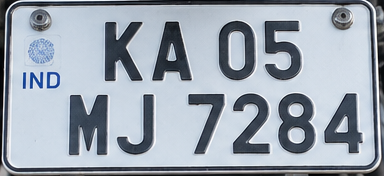

In [ ]:
import cv2
import os
from PIL import Image
from IPython.display import display

plate_crops = []

for i, box in enumerate(result.boxes):
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])

    if model.names[cls_id] != "number_plate":
        continue

    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    # Read original image
    image = cv2.imread(IMAGE_PATH)

    # Crop number plate
    plate_crop = image[y1:y2, x1:x2]

    if plate_crop.size == 0:
        continue

    # Convert BGR → RGB for display
    plate_crop_rgb = cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB)

    plate_crops.append({
        "crop": plate_crop_rgb,
        "confidence": confidence,
        "box": (x1, y1, x2, y2)
    })

print(f"Number plates detected: {len(plate_crops)}")

for i, plate in enumerate(plate_crops):
    print(
        f"Plate {i+1}: "
        f"confidence={plate['confidence']:.3f}, "
        f"box={plate['box']}"
    )

    display(Image.fromarray(plate["crop"]))

In [ ]:
for box in result.boxes:
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    print(
        f"class={model.names[cls_id]:12s} "
        f"confidence={confidence:.4f} "
        f"box=({x1},{y1},{x2},{y2})"
    )

class=number_plate confidence=0.2502 box=(556,391,940,567)


In [ ]:
low_conf_results = model.predict(
    source=IMAGE_PATH,
    conf=0.05,
    imgsz=640,
    verbose=False
)

low_result = low_conf_results[0]

print("Total detections:", len(low_result.boxes))

for box in low_result.boxes:
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"{model.names[cls_id]:12s} "
        f"confidence={confidence:.4f}"
    )

Total detections: 2
number_plate confidence=0.2502
rider        confidence=0.1004


In [ ]:
from PIL import Image
import os

print("Image path:", IMAGE_PATH)
print("Exists:", os.path.exists(IMAGE_PATH))

img = Image.open(IMAGE_PATH)

print("Image size:", img.size)
print("Image mode:", img.mode)

display(img)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# 640 resolution
result_640 = model.predict(
    source=IMAGE_PATH,
    conf=0.001,
    imgsz=640,
    verbose=False
)[0]

# 1280 resolution
result_1280 = model.predict(
    source=IMAGE_PATH,
    conf=0.001,
    imgsz=1280,
    verbose=False
)[0]

print("=== 640 ===")
for box in result_640.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    print(model.names[cls_id], f"{conf:.4f}")

print("\n=== 1280 ===")
for box in result_1280.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    print(model.names[cls_id], f"{conf:.4f}")

=== 640 ===
helmet 0.0291
rider 0.0102
helmet 0.0095
helmet 0.0040
helmet 0.0022
helmet 0.0012

=== 1280 ===
rider 0.2178
rider 0.0166
helmet 0.0079
rider 0.0018
rider 0.0011


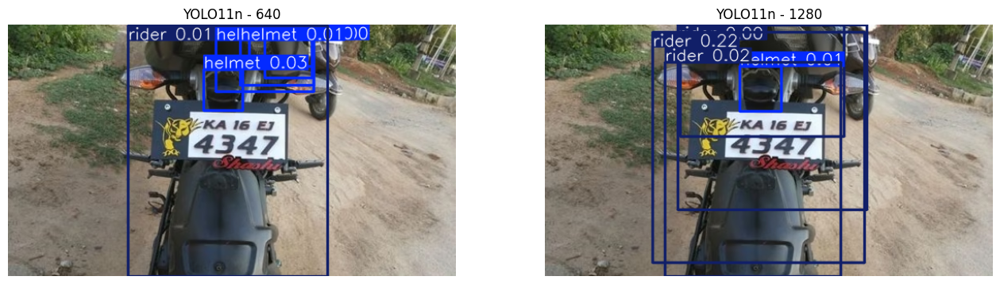

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(result_640.plot()[:, :, ::-1])
axes[0].set_title("YOLO11n - 640")
axes[0].axis("off")

axes[1].imshow(result_1280.plot()[:, :, ::-1])
axes[1].set_title("YOLO11n - 1280")
axes[1].axis("off")

plt.show()

Original: 550 x 309
Crop: (385, 232)


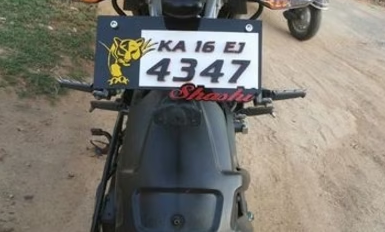

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(IMAGE_PATH)
width, height = img.size

print("Original:", width, "x", height)

# Lower-middle region
x1 = int(width * 0.15)
x2 = int(width * 0.85)
y1 = int(height * 0.25)
y2 = height

crop = img.crop((x1, y1, x2, y2))

print("Crop:", crop.size)

display(crop)

In [ ]:
import numpy as np

crop_path = "/content/plate_roi.jpg"
crop.save(crop_path)

crop_result = model.predict(
    source=crop_path,
    conf=0.001,
    imgsz=640,
    verbose=False
)[0]

print("Detections:", len(crop_result.boxes))

for box in crop_result.boxes:
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])

    x1b, y1b, x2b, y2b = box.xyxy[0].tolist()

    print(
        f"{model.names[cls_id]:12s} "
        f"confidence={confidence:.4f} "
        f"box=({x1b:.0f},{y1b:.0f},{x2b:.0f},{y2b:.0f})"
    )

Detections: 2
no_helmet    confidence=0.0492 box=(160,0,205,30)
helmet       confidence=0.0149 box=(158,0,206,30)


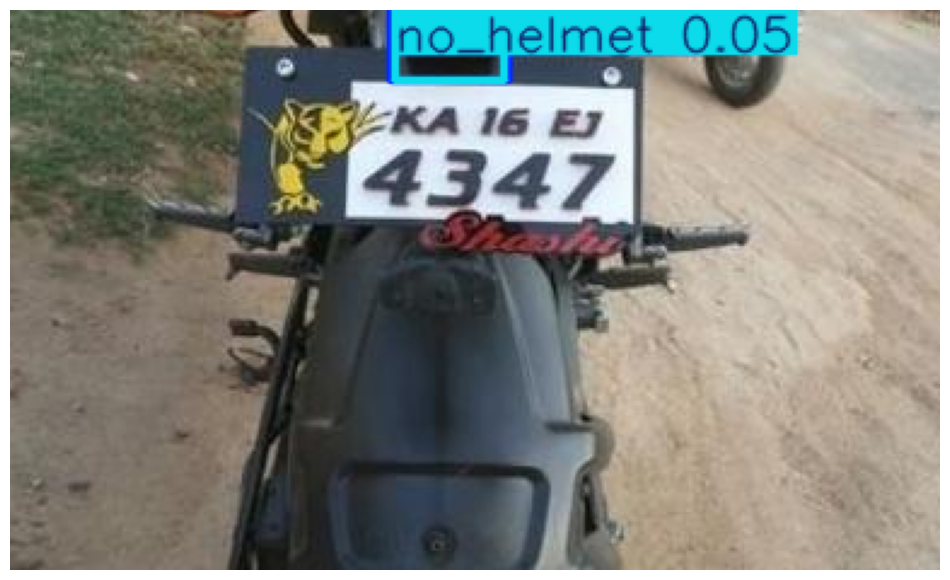

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(crop_result.plot()[:, :, ::-1])
plt.axis("off")
plt.show()

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="P5piyUkvrMQTzTSOMWvZ")
project = rf.workspace("car-plate-7a8nt").project("bike-number-plate-naen3")
version = project.version(1)
dataset = version.download("yolov11")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bike-Number-Plate-1 in yolov11:: 100%|██████████| 206/206 [00:00<00:00, 8972.43it/s]


In [ ]:
import os
import yaml

DATASET = "/content/Bike-Number-Plate-1"

print("Dataset contents:")
for item in os.listdir(DATASET):
    print(" -", item)

print("\n--- data.yaml ---")

yaml_path = os.path.join(DATASET, "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print(data)

Dataset contents:
 - data.yaml
 - train
 - README.dataset.txt
 - README.roboflow.txt

--- data.yaml ---
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['bike'], 'roboflow': {'workspace': 'car-plate-7a8nt', 'project': 'bike-number-plate-naen3', 'version': 1, 'license': 'Public Domain', 'url': 'https://universe.roboflow.com/car-plate-7a8nt/bike-number-plate-naen3/dataset/1'}}


In [ ]:
from pathlib import Path
from collections import Counter

DATASET = Path("/content/Bike-Number-Plate-1")

label_files = list((DATASET / "train" / "labels").glob("*.txt"))

class_ids = Counter()

for label_file in label_files:
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                class_ids[int(parts[0])] += 1

print("Number of label files:", len(label_files))
print("Class IDs:", class_ids)

Number of label files: 100
Class IDs: Counter({0: 101})


In [ ]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

DATASET = Path("/content/Bike-Number-Plate-1")

image_files = list((DATASET / "train" / "images").glob("*"))
random.seed(42)
sample_images = random.sample(image_files, min(9, len(image_files)))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_images):

    label_path = DATASET / "train" / "labels" / f"{img_path.stem}.txt"

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(
                img,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                3
            )

            cv2.putText(
                img,
                f"class {int(cls)}",
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (255, 0, 0),
                2
            )

    ax.imshow(img)
    ax.set_title(img_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
import shutil

SOURCE = Path("/content/drive/MyDrive/computervision/Helmet-&-Number-Plate-Detection-2-1")
NEW_DATA = Path("/content/Bike-Number-Plate-1")

MERGED = Path("/content/Helmet-NumberPlate-Merged")

if MERGED.exists():
    shutil.rmtree(MERGED)

shutil.copytree(SOURCE, MERGED)

print("Created:", MERGED)

Created: /content/Helmet-NumberPlate-Merged


In [ ]:
from pathlib import Path
import shutil

MERGED = Path("/content/Helmet-NumberPlate-Merged")
NEW_DATA = Path("/content/Bike-Number-Plate-1")

src_images = NEW_DATA / "train" / "images"
src_labels = NEW_DATA / "train" / "labels"

dst_images = MERGED / "train" / "images"
dst_labels = MERGED / "train" / "labels"

# Make sure destination folders exist
dst_images.mkdir(parents=True, exist_ok=True)
dst_labels.mkdir(parents=True, exist_ok=True)

image_files = list(src_images.glob("*"))

copied_images = 0
copied_labels = 0
total_boxes = 0

for img_path in image_files:
    label_path = src_labels / f"{img_path.stem}.txt"

    # Use a unique filename to avoid collisions
    new_name = f"bikeplate_{img_path.name}"
    new_label_name = f"bikeplate_{img_path.stem}.txt"

    # Copy image
    shutil.copy2(img_path, dst_images / new_name)
    copied_images += 1

    # Remap class 0 -> class 2
    new_lines = []

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, x, y, w, h = parts

            if int(cls) != 0:
                raise ValueError(
                    f"Unexpected class {cls} in {label_path}"
                )

            new_lines.append(f"2 {x} {y} {w} {h}\n")
            total_boxes += 1

    with open(dst_labels / new_label_name, "w") as f:
        f.writelines(new_lines)

    copied_labels += 1

print("Merge completed.")
print("Images added :", copied_images)
print("Labels added :", copied_labels)
print("Boxes added  :", total_boxes)

Merge completed.
Images added : 100
Labels added : 100
Boxes added  : 101


In [ ]:
from pathlib import Path
from collections import Counter

DATASET = Path("/content/Helmet-NumberPlate-Merged")

# Count images and labels
train_images = list((DATASET / "train" / "images").glob("*"))
train_labels = list((DATASET / "train" / "labels").glob("*.txt"))

valid_images = list((DATASET / "valid" / "images").glob("*"))
test_images = list((DATASET / "test" / "images").glob("*"))

print("TRAIN images :", len(train_images))
print("TRAIN labels :", len(train_labels))
print("VALID images :", len(valid_images))
print("TEST images  :", len(test_images))

# Count classes in training labels
class_counts = Counter()
box_count = 0

for label_file in train_labels:
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls = int(parts[0])
            class_counts[cls] += 1
            box_count += 1

print("\nTraining boxes:", box_count)
print("Class counts:", class_counts)

# Specifically verify our 100 added files
new_label_files = list(
    (DATASET / "train" / "labels").glob("bikeplate_*.txt")
)

new_class_counts = Counter()

for label_file in new_label_files:
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                new_class_counts[int(parts[0])] += 1

print("\nNew bike-plate label files:", len(new_label_files))
print("New bike-plate class counts:", new_class_counts)

TRAIN images : 4480
TRAIN labels : 4480
VALID images : 616
TEST images  : 376

Training boxes: 9012
Class counts: Counter({0: 3266, 1: 3043, 4: 1674, 2: 604, 3: 425})

New bike-plate label files: 100
New bike-plate class counts: Counter({2: 101})


In [ ]:
from ultralytics import YOLO

MODEL_PATH = "/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt"

model = YOLO(MODEL_PATH)

results = model.val(
    data="/content/Bike-Number-Plate-1/data.yaml",
    imgsz=640,
    batch=16,
    device=0,
    split="train"
)

print("Evaluation complete.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1193.7±302.7 MB/s, size: 50.4 KB)
val: Scanning /content/Bike-Number-Plate-1/train/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.1Kit/s 0.1s
val: New cache created: /content/Bike-Number-Plate-1/train/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.3it/s 5.6s
                   all        100        101      0.297      0.267     0.0922     0.0265
                helmet        100        101      0.297      0.267     0.0922     0.0265
Speed: 16.6ms preprocess, 10.7ms inference, 0.0ms loss, 7.0ms postprocess per image
Results saved to /content/runs/detect/val
Evaluation complete.


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt"
DATASET = Path("/content/Bike-Number-Plate-1")

model = YOLO(MODEL_PATH)

image_files = list((DATASET / "train" / "images").glob("*"))

TP = 0
FP = 0
FN = 0

for img_path in image_files:

    label_path = DATASET / "train" / "labels" / f"{img_path.stem}.txt"

    # Ground-truth boxes
    gt_boxes = []

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            _, xc, yc, w, h = map(float, parts)

            gt_boxes.append([
                xc - w / 2,
                yc - h / 2,
                xc + w / 2,
                yc + h / 2
            ])

    # YOLO prediction
    result = model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.001,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    for box, cls in zip(result.boxes.xyxy.cpu().numpy(),
                         result.boxes.cls.cpu().numpy()):

        # Only class 2 = number_plate
        if int(cls) == 2:
            x1, y1, x2, y2 = box

            h_img, w_img = result.orig_shape

            pred_boxes.append([
                x1 / w_img,
                y1 / h_img,
                x2 / w_img,
                y2 / h_img
            ])

    matched_gt = set()

    for pred in pred_boxes:

        best_iou = 0
        best_gt = None

        for i, gt in enumerate(gt_boxes):

            if i in matched_gt:
                continue

            ix1 = max(pred[0], gt[0])
            iy1 = max(pred[1], gt[1])
            ix2 = min(pred[2], gt[2])
            iy2 = min(pred[3], gt[3])

            inter_w = max(0, ix2 - ix1)
            inter_h = max(0, iy2 - iy1)

            inter = inter_w * inter_h

            area_pred = (
                (pred[2] - pred[0]) *
                (pred[3] - pred[1])
            )

            area_gt = (
                (gt[2] - gt[0]) *
                (gt[3] - gt[1])
            )

            union = area_pred + area_gt - inter

            iou = inter / union if union > 0 else 0

            if iou > best_iou:
                best_iou = iou
                best_gt = i

        if best_iou >= 0.5:
            TP += 1
            matched_gt.add(best_gt)
        else:
            FP += 1

    FN += len(gt_boxes) - len(matched_gt)

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0

print("\nNUMBER PLATE BASELINE")
print("----------------------")
print("Ground truth :", TP + FN)
print("TP           :", TP)
print("FP           :", FP)
print("FN           :", FN)
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")


NUMBER PLATE BASELINE
----------------------
Ground truth : 101
TP           : 65
FP           : 52
FN           : 36
Precision    : 0.5556
Recall       : 0.6436


In [ ]:
from pathlib import Path
import random
import shutil

SRC = Path("/content/Helmet-NumberPlate-Merged")

EXP = Path("/content/plate_finetune_100")
if EXP.exists():
    shutil.rmtree(EXP)

for split in ["train", "valid"]:
    (EXP / split / "images").mkdir(parents=True)
    (EXP / split / "labels").mkdir(parents=True)

# Only the 100 newly-added images
images = list((SRC / "train" / "images").glob("bikeplate_*"))

random.seed(42)
random.shuffle(images)

train_imgs = images[:80]
valid_imgs = images[80:]

for img in train_imgs:
    label = SRC / "train" / "labels" / f"{img.stem}.txt"

    shutil.copy2(img, EXP / "train" / "images" / img.name)
    shutil.copy2(label, EXP / "train" / "labels" / label.name)

for img in valid_imgs:
    label = SRC / "train" / "labels" / f"{img.stem}.txt"

    shutil.copy2(img, EXP / "valid" / "images" / img.name)
    shutil.copy2(label, EXP / "valid" / "labels" / label.name)

print("Training images :", len(train_imgs))
print("Validation images:", len(valid_imgs))

Training images : 80
Validation images: 20


In [ ]:
import yaml

data = {
    "train": str(EXP / "train" / "images"),
    "val": str(EXP / "valid" / "images"),
    "nc": 5,
    "names": [
        "helmet",
        "no_helmet",
        "number_plate",
        "pillion",
        "rider"
    ]
}

yaml_path = EXP / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(yaml_path)

/content/plate_finetune_100/data.yaml


In [ ]:
from ultralytics import YOLO

BASE_MODEL = (
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

model = YOLO(BASE_MODEL)

results = model.train(
    data=str(yaml_path),

    epochs=20,
    imgsz=640,
    batch=16,
    device=0,

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.1,

    freeze=10,

    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    patience=5,

    workers=2,
    amp=True,

    project="/content/drive/MyDrive/computervision/runs",
    name="yolo11n_plate_100_finetune",
    save=True
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plate_finetune_100/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt, momentum=0.937, mosaic=0

In [ ]:
from ultralytics import YOLO

FINETUNED_MODEL = (
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_plate_100_finetune/weights/best.pt"
)

model_plate = YOLO(FINETUNED_MODEL)

print("Model loaded")
print(model_plate.names)

Model loaded
{0: 'helmet', 1: 'no_helmet', 2: 'number_plate', 3: 'pillion', 4: 'rider'}


In [ ]:
results = model_plate(
    "/content/szAA_1652525216370_1652525223708.avif",
    imgsz=640,
    conf=0.001
)

for r in results:
    print("\nDetections:")
    for box in r.boxes:
        cls = int(box.cls[0])
        conf = float(box.conf[0])

        print(
            f"{model_plate.names[cls]} "
            f"confidence={conf:.4f} "
            f"box={box.xyxy[0].tolist()}"
        )


image 1/1 /content/szAA_1652525216370_1652525223708.avif: 384x640 5 helmets, 3 number_plates, 2 riders, 11.9ms
Speed: 1.4ms preprocess, 11.9ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)

Detections:
number_plate confidence=0.8236 box=[169.88681030273438, 101.26858520507812, 356.1540222167969, 179.31295776367188]
helmet confidence=0.0363 box=[209.4260711669922, 1.0808796882629395, 391.97821044921875, 80.06623840332031]
number_plate confidence=0.0283 box=[159.60787963867188, 148.52464294433594, 352.4333801269531, 309.0]
helmet confidence=0.0143 box=[252.39315795898438, 0.0, 394.4658203125, 63.814247131347656]
helmet confidence=0.0038 box=[237.27186584472656, 54.38978958129883, 293.9456787109375, 106.52525329589844]
helmet confidence=0.0026 box=[270.9036865234375, 0.0, 385.8870849609375, 45.685123443603516]
rider confidence=0.0018 box=[0.085764080286026, 20.388690948486328, 25.260223388671875, 271.2136535644531]
rider confidence=0.0017 box=[160.82435607910156, 156.9

In [ ]:
TEST_YAML = "/content/Helmet-&-Number-Plate-Detection-2-1/data.yaml"

test_results = model_plate.val(
    data=TEST_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

print(test_results.results_dict)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 92.9±81.7 MB/s, size: 572.6 KB)
val: Scanning /content/Helmet-&-Number-Plate-Detection-2-1/test/labels... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376 401.7it/s 0.9s
val: New cache created: /content/Helmet-&-Number-Plate-Detection-2-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 2.1it/s 11.5s
                   all        376        761      0.812      0.803      0.865      0.435
                helmet        161        257      0.809      0.712       0.79      0.358
             no_helmet        104        171      0.909      0.673      0.846      0.419
          number_plate         65         68      0.487      0.868       0.81      0.246
               pillion     

In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/Helmet-NumberPlate-Merged")

for split in ["train", "valid", "test"]:
    img_dir = ROOT / split / "images"
    lbl_dir = ROOT / split / "labels"

    images = list(img_dir.glob("*"))
    labels = list(lbl_dir.glob("*.txt"))

    counts = Counter()

    for label_file in labels:
        for line in label_file.read_text().splitlines():
            if line.strip():
                cls = int(line.split()[0])
                counts[cls] += 1

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Labels :", len(labels))
    print("Boxes  :", sum(counts.values()))
    print("Classes:", counts)


TRAIN
Images : 4480
Labels : 4480
Boxes  : 9012
Classes: Counter({0: 3266, 1: 3043, 4: 1674, 2: 604, 3: 425})

VALID
Images : 616
Labels : 616
Boxes  : 1352
Classes: Counter({1: 596, 0: 452, 4: 165, 2: 83, 3: 56})

TEST
Images : 376
Labels : 376
Boxes  : 761
Classes: Counter({0: 257, 4: 210, 1: 171, 2: 68, 3: 55})


In [ ]:
from pathlib import Path
import yaml

ROOT = Path("/content/Helmet-NumberPlate-Merged")

data = {
    "path": str(ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "helmet",
        "no_helmet",
        "number_plate",
        "pillion",
        "rider"
    ]
}

YAML_PATH = ROOT / "data_combined.yaml"

with open(YAML_PATH, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(YAML_PATH)
print(YAML_PATH.read_text())

/content/Helmet-NumberPlate-Merged/data_combined.yaml
path: /content/Helmet-NumberPlate-Merged
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- helmet
- no_helmet
- number_plate
- pillion
- rider



In [ ]:
from pathlib import Path
import yaml

ROOT = Path("/content/drive/MyDrive/computervision/Helmet-NumberPlate-Merged")

data = {
    "path": str(ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "helmet",
        "no_helmet",
        "number_plate",
        "pillion",
        "rider"
    ]
}

YAML_PATH = ROOT / "data_combined.yaml"

with open(YAML_PATH, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(YAML_PATH)
print(YAML_PATH.read_text())

/content/drive/MyDrive/computervision/Helmet-NumberPlate-Merged/data_combined.yaml
path: /content/drive/MyDrive/computervision/Helmet-NumberPlate-Merged
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- helmet
- no_helmet
- number_plate
- pillion
- rider



In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/computervision/"
    "Helmet-NumberPlate-Merged"
)

print("Dataset exists:", ROOT.exists())
print("YAML exists:", (ROOT / "data_combined.yaml").exists())

print("\nDataset:")
for split in ["train", "valid", "test"]:
    print(
        split,
        "images =", len(list((ROOT / split / "images").glob("*"))),
        "labels =", len(list((ROOT / split / "labels").glob("*.txt")))
    )

Dataset exists: True
YAML exists: True

Dataset:
train images = 4480 labels = 4480
valid images = 616 labels = 616
test images = 376 labels = 376


In [ ]:
!pip install ultralytics
from ultralytics import YOLO

BASE_MODEL = (
    "/content/drive/MyDrive/computervision/runs/"
    "yolo11n_helmet_plate_baseline/weights/best.pt"
)

DATA_YAML = (
    "/content/drive/MyDrive/computervision/"
    "Helmet-NumberPlate-Merged/data_combined.yaml"
)

model = YOLO(BASE_MODEL)

results = model.train(
    data=DATA_YAML,

    epochs=20,
    imgsz=640,
    batch=16,
    device=0,

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.1,

    freeze=10,

    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    patience=5,

    workers=2,
    amp=True,

    project="/content/drive/MyDrive/computervision/runs",
    name="yolo11n_combined_plate_adaptation",

    save=True,
    save_period=5
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 747.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 7.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/computervision/runs/yolo11n_helmet_plate_baseline/weights/best.pt'

In [2]:
from ultralytics import YOLO

BASE_MODEL = (
"runs/yolo11n_helmet_plate_baseline/weights/best.pt"
)

DATA_YAML = (
"Helmet-NumberPlate-Merged/data_combined.yaml"
)

model = YOLO(BASE_MODEL)

results = model.train(
    data=DATA_YAML,

    epochs=20,
    imgsz=640,
    batch=16,
    device=0,

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.1,

    freeze=10,

    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    patience=5,

    workers=2,
    amp=True,

    project="runs",
    name="yolo11n_combined_plate_adaptation",

    save=True,
    save_period=5
)

WARNING Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\heman\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu 


ValueError: Invalid CUDA 'device=0' requested. Use 'device=cpu' or pass valid CUDA device(s) if available, i.e. 'device=0' or 'device=0,1,2,3' for Multi-GPU.

torch.cuda.is_available(): False
torch.cuda.device_count(): 0
os.environ['CUDA_VISIBLE_DEVICES']: None
See https://pytorch.org/get-started/locally/ for up-to-date torch install instructions if no CUDA devices are seen by torch.


In [4]:
import inspect
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)

model = YOLO(BASE_MODEL)

print("\nTraining device support check:")
print(inspect.signature(model.train))

Ultralytics version: 8.4.171

Training device support check:
(trainer=None, **kwargs: 'Any')


In [5]:
results = model.train(
    data=DATA_YAML,
    epochs=1,
    imgsz=640,
    batch=4,
    device="xpu:0",
    workers=0,
    project="runs",
    name="yolo11n_xpu_test",
    exist_ok=True,
    plots=False
)

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Helmet-NumberPlate-Merged/data_combined.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=r

RuntimeError: Dataset 'Helmet-NumberPlate-Merged/data_combined.yaml' error  Dataset 'Helmet-NumberPlate-Merged/data_combined.yaml' images not found, missing path 'C:\content\drive\MyDrive\computervision\Helmet-NumberPlate-Merged\valid\images'
Note dataset download directory is 'C:\Users\datasets'. You can update this in 'C:\Users\heman\AppData\Roaming\Ultralytics\settings.json'

In [6]:
from pathlib import Path

PROJECT_DIR = Path(r"G:\My Drive\computervision")
DATA_YAML = PROJECT_DIR / "Helmet-NumberPlate-Merged" / "data_combined.yaml"

print("YAML exists:", DATA_YAML.exists())

if DATA_YAML.exists():
    print(DATA_YAML.read_text(encoding="utf-8"))

YAML exists: True
path: /content/drive/MyDrive/computervision/Helmet-NumberPlate-Merged
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- helmet
- no_helmet
- number_plate
- pillion
- rider



In [2]:
from pathlib import Path
import yaml

PROJECT_DIR = Path(r"G:\My Drive\computervision")
DATASET_DIR = PROJECT_DIR / "Helmet-NumberPlate-Merged"
DATA_YAML = DATASET_DIR / "data_combined.yaml"

assert DATASET_DIR.exists(), f"Dataset folder not found: {DATASET_DIR}"
assert DATA_YAML.exists(), f"YAML not found: {DATA_YAML}"

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

data["path"] = str(DATASET_DIR)
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Updated YAML:", DATA_YAML)
print(DATA_YAML.read_text(encoding="utf-8"))

Updated YAML: G:\My Drive\computervision\Helmet-NumberPlate-Merged\data_combined.yaml
path: G:\My Drive\computervision\Helmet-NumberPlate-Merged
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- helmet
- no_helmet
- number_plate
- pillion
- rider



In [3]:
for split in ["train", "valid", "test"]:
    image_dir = DATASET_DIR / split / "images"
    print(f"{split}: exists={image_dir.exists()}")

    if image_dir.exists():
        print("  Images:", len(list(image_dir.glob("*"))))

train: exists=True
  Images: 4480
valid: exists=True
  Images: 616
test: exists=True
  Images: 376


In [9]:
from ultralytics import YOLO

BASE_MODEL = (
    PROJECT_DIR
    / "runs"
    / "yolo11n_helmet_plate_baseline"
    / "weights"
    / "best.pt"
)

assert BASE_MODEL.exists(), f"Model checkpoint not found: {BASE_MODEL}"

model = YOLO(str(BASE_MODEL))

results = model.train(
    data=str(DATA_YAML),
    epochs=1,
    imgsz=640,
    batch=4,
    device="xpu:0",
    workers=0,
    project=str(PROJECT_DIR / "runs"),
    name="yolo11n_xpu_test",
    exist_ok=True,
    plots=False
)

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\My Drive\computervision\Helmet-NumberPlate-Merged\data_combined.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mix

In [1]:
from pathlib import Path
from ultralytics import YOLO
import torch

# ==========================================
# 1. PROJECT PATHS
# ==========================================
PROJECT_DIR = Path(r"G:\My Drive\computervision")

BASE_MODEL = (
    PROJECT_DIR
    / "runs"
    / "yolo11n_helmet_plate_baseline"
    / "weights"
    / "best.pt"
)

DATA_YAML = (
    PROJECT_DIR
    / "Helmet-NumberPlate-Merged"
    / "data_combined.yaml"
)

RUNS_DIR = PROJECT_DIR / "runs"

# ==========================================
# 2. VERIFY FILES AND GPU
# ==========================================
assert BASE_MODEL.exists(), f"Baseline model not found: {BASE_MODEL}"
assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"

assert hasattr(torch, "xpu") and torch.xpu.is_available(), (
    "Intel XPU is unavailable. Check your yoloxpu environment."
)

print("PyTorch:", torch.__version__)
print("GPU:", torch.xpu.get_device_name(0))
print("Starting model:", BASE_MODEL)
print("Dataset:", DATA_YAML)

# ==========================================
# 3. LOAD ORIGINAL BASELINE MODEL
# ==========================================
model = YOLO(str(BASE_MODEL))

# ==========================================
# 4. START FINE-TUNING
# ==========================================
results = model.train(
    data=str(DATA_YAML),

    # Training configuration
    epochs=20,
    imgsz=640,
    batch=4,

    # Intel Arc GPU
    device="xpu:0",
    amp=False,
    workers=0,

    # Optimizer and learning rate
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.1,
    freeze=10,

    # Disable additional augmentation for fine-tuning
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    # Output configuration
    project=str(RUNS_DIR),
    name="yolo11n_combined_finetune_final",
    exist_ok=True,

    # Checkpoints
    save=True,
    save_period=5,

    # Stop early if validation stops improving
    patience=7,

    # Reproducibility
    seed=42,

    # Logging
    plots=False,
    verbose=True
)

# ==========================================
# 5. DISPLAY OUTPUT
# ==========================================
OUTPUT_DIR = RUNS_DIR / "yolo11n_combined_finetune_final"

print("\nFine-tuning finished.")
print("Results saved in:", OUTPUT_DIR)
print("Best model:", OUTPUT_DIR / "weights" / "best.pt")
print("Last checkpoint:", OUTPUT_DIR / "weights" / "last.pt")

PyTorch: 2.14.1+xpu
GPU: Intel(R) Arc(TM) Graphics
Starting model: G:\My Drive\computervision\runs\yolo11n_helmet_plate_baseline\weights\best.pt
Dataset: G:\My Drive\computervision\Helmet-NumberPlate-Merged\data_combined.yaml
New https://pypi.org/project/ultralytics/8.4.185 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\My Drive\computervision\Helmet-NumberPlate-Merged\data_combined.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, era

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [3]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("XPU available:", torch.xpu.is_available())

if torch.xpu.is_available():
    print("GPU:", torch.xpu.get_device_name(0))
    print("Allocated memory:", torch.xpu.memory_allocated(0))
    print("Reserved memory:", torch.xpu.memory_reserved(0))

PyTorch: 2.14.1+xpu
Ultralytics: 8.4.171
XPU available: True
GPU: Intel(R) Arc(TM) Graphics
Allocated memory: 40739840
Reserved memory: 109051904


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("XPU available:", torch.xpu.is_available())

if torch.xpu.is_available():
    print("GPU:", torch.xpu.get_device_name(0))

    try:
        # Test basic GPU computation
        a = torch.randn(2, 3, device="xpu:0")
        b = torch.randn(2, 3, device="xpu:0")
        c = a + b

        torch.xpu.synchronize()
        print("Basic XPU addition: SUCCESS")
        print(c)

    except Exception as e:
        print("Basic XPU addition: FAILED")
        print(type(e).__name__, e)

PyTorch: 2.14.1+xpu
XPU available: True
GPU: Intel(R) Arc(TM) Graphics
Basic XPU addition: SUCCESS
tensor([[ 0.0398,  0.5372, -2.1369],
        [ 3.0108, -1.9059, -0.6667]], device='xpu:0')


In [2]:
import torch
import torch.nn as nn

try:
    conv = nn.Conv2d(3, 16, kernel_size=3, padding=1).to("xpu:0")
    x = torch.randn(1, 3, 320, 320, device="xpu:0")

    with torch.no_grad():
        y = conv(x)

    torch.xpu.synchronize()

    print("XPU convolution: SUCCESS")
    print("Output shape:", y.shape)

except Exception as e:
    print("XPU convolution: FAILED")
    print(type(e).__name__, e)

XPU convolution: FAILED
RuntimeError could not make an engine with allocator


In [3]:
import torch
import torch.nn as nn

conv = nn.Conv2d(3, 16, kernel_size=3, padding=1)
x = torch.randn(1, 3, 320, 320)

with torch.no_grad():
    y = conv(x)

print("CPU convolution: SUCCESS")
print("Output shape:", y.shape)

CPU convolution: SUCCESS
Output shape: torch.Size([1, 16, 320, 320])


In [5]:
import torch
import torch.nn as nn

conv = nn.Conv2d(3, 16, kernel_size=3, padding=1)
x = torch.randn(1, 3, 320, 320)

with torch.no_grad():
    y = conv(x)

print("CPU convolution: SUCCESS")
print("Output shape:", y.shape)

CPU convolution: SUCCESS
Output shape: torch.Size([1, 16, 320, 320])


In [7]:
import torch
import torchvision
import importlib.metadata as md

for package in ["torch", "torchvision"]:
    dist = md.distribution(package)
    print(f"\n{package}")
    print("Version:", dist.version)
    print("Location:", dist.locate_file(""))
    print("Installer:", dist.read_text("INSTALLER"))
    print("Direct URL:", dist.read_text("direct_url.json"))

print("\nPyTorch XPU available:", torch.xpu.is_available())
print("Torchvision:", torchvision.__version__)


torch
Version: 2.14.1+xpu
Location: C:\Users\heman\anaconda3\envs\yoloxpu\Lib\site-packages
Installer: pip

Direct URL: None

torchvision
Version: 0.29.1+xpu
Location: C:\Users\heman\anaconda3\envs\yoloxpu\Lib\site-packages
Installer: pip

Direct URL: None

PyTorch XPU available: True
Torchvision: 0.29.1+xpu


In [4]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final"
)

WEIGHTS_DIR = RUN_DIR / "weights"

print("Run directory exists:", RUN_DIR.exists())

for name in ["best.pt", "last.pt"]:
    path = WEIGHTS_DIR / name
    if path.exists():
        print(f"{name}: {path.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"{name}: NOT FOUND")

results_file = RUN_DIR / "results.csv"

if results_file.exists():
    df = pd.read_csv(results_file)
    print("\nEpochs recorded:", len(df))
    print("Last recorded epoch:", df.iloc[-1, 0])
    display(df.tail())
else:
    print("results.csv not found")

Run directory exists: True
best.pt: 5.19 MB
last.pt: 5.19 MB

Epochs recorded: 15
Last recorded epoch: 15


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
10,11,4688.56,0.96001,0.55723,1.08202,0.78399,0.76895,0.81271,0.47731,1.37243,0.91837,1.33061,0.000275,0.000275,0.000275
11,12,5095.03,0.95225,0.55253,1.07302,0.74300,0.76559,0.80239,0.47294,1.38751,0.92383,1.33924,0.000253,0.000253,0.000253
12,13,5487.01,0.94466,0.54660,1.06920,0.76724,0.76659,0.80653,0.47742,1.38498,0.91714,1.35712,0.000230,0.000230,0.000230
13,14,5883.73,0.94067,0.53638,1.06612,0.75332,0.75284,0.78678,0.46617,1.38824,0.95264,1.33634,0.000208,0.000208,0.000208
14,15,6277.24,0.93121,0.53500,1.06161,0.75355,0.77254,0.80050,0.46640,1.38466,0.91897,1.34362,0.000185,0.000185,0.000185


In [5]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final"
)

results_file = RUN_DIR / "results.csv"
weights_dir = RUN_DIR / "weights"

if results_file.exists():
    df = pd.read_csv(results_file)

    print("Epochs recorded:", len(df))
    print("Last epoch recorded:", df.iloc[-1]["epoch"])

    print("\nCheckpoint files:")
    for filename in ["best.pt", "last.pt"]:
        path = weights_dir / filename
        print(filename, "exists:", path.exists())
else:
    print("results.csv not found")

Epochs recorded: 15
Last epoch recorded: 15.0

Checkpoint files:
best.pt exists: True
last.pt exists: True


In [6]:
import pandas as pd
from pathlib import Path

RUN_DIR = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final"
)

df = pd.read_csv(RUN_DIR / "results.csv")

metric_cols = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
]

print(df[metric_cols].tail(5).to_string(index=False))

best_idx = df["metrics/mAP50(B)"].idxmax()
print("\nBest recorded epoch by mAP50:", df.loc[best_idx, "epoch"])
print("Best recorded mAP50:", df.loc[best_idx, "metrics/mAP50(B)"])

 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    11               0.78399            0.76895           0.81271              0.47731
    12               0.74300            0.76559           0.80239              0.47294
    13               0.76724            0.76659           0.80653              0.47742
    14               0.75332            0.75284           0.78678              0.46617
    15               0.75355            0.77254           0.80050              0.46640

Best recorded epoch by mAP50: 4
Best recorded mAP50: 0.82393


In [7]:
from pathlib import Path
import torch

LAST_PT = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\weights\last.pt"
)

checkpoint = torch.load(
    LAST_PT,
    map_location="cpu",
    weights_only=False,
)

print("Checkpoint keys:", list(checkpoint.keys()))
print("Saved epoch:", checkpoint.get("epoch"))
print("Optimizer state available:", checkpoint.get("optimizer") is not None)
print("Training results saved:", checkpoint.get("train_results") is not None)

Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git']
Saved epoch: -1
Optimizer state available: False
Training results saved: True


In [8]:
from pathlib import Path
from datetime import datetime
import shutil

RUN_DIR = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final"
)

BACKUP_DIR = RUN_DIR / f"backup_before_resume_{datetime.now():%Y%m%d_%H%M%S}"
BACKUP_DIR.mkdir(parents=True, exist_ok=False)

files_to_backup = [
    RUN_DIR / "weights" / "best.pt",
    RUN_DIR / "weights" / "last.pt",
    RUN_DIR / "results.csv",
]

for src in files_to_backup:
    if src.exists():
        dest = BACKUP_DIR / src.name
        shutil.copy2(src, dest)
        print(f"Backed up: {src.name} -> {dest}")
    else:
        print(f"Not found: {src}")

print("\nBackup location:", BACKUP_DIR)

Backed up: best.pt -> G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\backup_before_resume_20261024_145049\best.pt
Backed up: last.pt -> G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\backup_before_resume_20261024_145049\last.pt
Backed up: results.csv -> G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\backup_before_resume_20261024_145049\results.csv

Backup location: G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\backup_before_resume_20261024_145049


In [9]:
from pathlib import Path
from ultralytics import YOLO

LAST_PT = Path(
    r"G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\weights\last.pt"
)

model = YOLO(str(LAST_PT))

print("Saved training arguments:")
for key, value in model.ckpt.get("train_args", {}).items():
    if key in [
        "data", "epochs", "imgsz", "batch", "device",
        "optimizer", "resume", "project", "name",
    ]:
        print(f"{key}: {value}")

Saved training arguments:
data: G:\My Drive\computervision\Helmet-NumberPlate-Merged\data_combined.yaml
epochs: 20
batch: 4
imgsz: 640
device: xpu:0
project: G:\My Drive\computervision\runs
name: yolo11n_combined_finetune_final
optimizer: AdamW
resume: False


In [10]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"G:\My Drive\computervision")
RUN_DIR = PROJECT_DIR / "runs" / "yolo11n_combined_finetune_final"
BEST_PT = RUN_DIR / "weights" / "best.pt"

assert BEST_PT.exists(), f"Checkpoint not found: {BEST_PT}"

model = YOLO(str(BEST_PT))
print("Loaded:", BEST_PT)
print("Model classes:", model.names)

Loaded: G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\weights\best.pt
Model classes: {0: 'helmet', 1: 'no_helmet', 2: 'number_plate', 3: 'pillion', 4: 'rider'}


In [12]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path(r"G:\My Drive\computervision")

DATA_YAML = (
    PROJECT_DIR
    / "Helmet-NumberPlate-Merged"
    / "data_combined.yaml"
)

BEST_PT = (
    PROJECT_DIR
    / "runs"
    / "yolo11n_combined_finetune_final"
    / "weights"
    / "best.pt"
)

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"
assert BEST_PT.exists(), f"Model checkpoint not found: {BEST_PT}"

model = YOLO(str(BEST_PT))

print("Evaluating:", BEST_PT)
print("Device: Intel Arc GPU")

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=1,
    device="xpu:0",
    workers=0,
    plots=True,
    project=str(PROJECT_DIR / "runs"),
    name="combined_finetune_test_evaluation",
    exist_ok=True,
)

torch.xpu.synchronize()

print("\nTEST RESULTS")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))

print("\nPer-class mAP50:")
for class_id, score in enumerate(metrics.box.ap50):
    print(f"{model.names[class_id]}: {score:.4f}")

Evaluating: G:\My Drive\computervision\runs\yolo11n_combined_finetune_final\weights\best.pt
Device: Intel Arc GPU
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.80.2 ms, read: 0.40.5 MB/s, size: 647.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\My Drive\computervision\Helmet-NumberPlate-Merged\test\labels... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376 8.9it/s 42.4s0.7sss
val: New cache created: G:\My Drive\computervision\Helmet-NumberPlate-Merged\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 376/376 3.5it/s 1:470.1ssss
                   all        376        761      0.871      0.864      0.916      0.556


In [13]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path(r"G:\My Drive\computervision")

DATA_YAML = (
    PROJECT_DIR
    / "Helmet-NumberPlate-Merged"
    / "data_combined.yaml"
)

BASELINE_PT = (
    PROJECT_DIR
    / "runs"
    / "yolo11n_helmet_plate_baseline"
    / "weights"
    / "best.pt"
)

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"
assert BASELINE_PT.exists(), f"Baseline checkpoint not found: {BASELINE_PT}"

baseline = YOLO(str(BASELINE_PT))

print("Evaluating original baseline:", BASELINE_PT)

baseline_metrics = baseline.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=1,
    device="xpu:0",
    workers=0,
    plots=True,
    project=str(PROJECT_DIR / "runs"),
    name="baseline_test_evaluation",
    exist_ok=True,
)

torch.xpu.synchronize()

print("\nBASELINE TEST RESULTS")
print("Precision:", round(baseline_metrics.box.mp, 4))
print("Recall:", round(baseline_metrics.box.mr, 4))
print("mAP50:", round(baseline_metrics.box.map50, 4))
print("mAP50-95:", round(baseline_metrics.box.map, 4))

print("\nPer-class mAP50:")
for class_id, score in enumerate(baseline_metrics.box.ap50):
    print(f"{baseline.names[class_id]}: {score:.4f}")

Evaluating original baseline: G:\My Drive\computervision\runs\yolo11n_helmet_plate_baseline\weights\best.pt
Ultralytics 8.4.171  Python-3.12.14 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.70.1 ms, read: 14.18.1 MB/s, size: 96.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\My Drive\computervision\Helmet-NumberPlate-Merged\test\labels.cache... 376 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 376/376  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 376/376 5.5it/s 1:080.3ssss
                   all        376        761      0.871      0.879      0.917      0.567
                helmet        161        257      0.813      0.794      0.858      0.457
             no_helm

In [14]:
from pathlib import Path
import shutil

# Original project directory
SOURCE = Path(r"G:\My Drive\computervision")

# New clean project directory
DEST = Path(r"G:\My Drive\helmet-number-plate-detection")

# Create destination folders
(DEST / "models").mkdir(parents=True, exist_ok=True)
(DEST / "notebooks").mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Copy the working Jupyter notebook
# --------------------------------------------------
notebook_name = "helmet_plate_intel_arc_training.ipynb"
notebook_source = SOURCE / notebook_name
notebook_destination = DEST / "notebooks" / notebook_name

if notebook_source.exists():
    shutil.copy2(notebook_source, notebook_destination)
    print(f"Notebook copied: {notebook_destination}")
else:
    print(f"Notebook not found at: {notebook_source}")
    print("Update notebook_source with the actual notebook path.")

# --------------------------------------------------
# 2. Copy the original baseline best model
# --------------------------------------------------
model_source = (
    SOURCE
    / "runs"
    / "yolo11n_helmet_plate_baseline"
    / "weights"
    / "best.pt"
)

model_destination = DEST / "models" / "best.pt"

if model_source.exists():
    shutil.copy2(model_source, model_destination)
    print(f"\nModel copied: {model_destination}")
    print(f"Model size: {model_destination.stat().st_size / (1024**2):.2f} MB")
else:
    print(f"Model not found at: {model_source}")

print("\nCopy operation completed.")

Notebook not found at: G:\My Drive\computervision\helmet_plate_intel_arc_training.ipynb
Update notebook_source with the actual notebook path.

Model copied: G:\My Drive\helmet-number-plate-detection\models\best.pt
Model size: 5.19 MB

Copy operation completed.


In [15]:
from pathlib import Path

DEST = Path(r"G:\My Drive\helmet-number-plate-detection")

print("PROJECT FILES")
print("=" * 60)

if DEST.exists():
    for path in sorted(DEST.rglob("*")):
        if path.is_file():
            size_mb = path.stat().st_size / (1024**2)
            print(f"{path.relative_to(DEST)}  |  {size_mb:.2f} MB")
else:
    print("Project directory does not exist.")

PROJECT FILES
models\best.pt  |  5.19 MB
